# Cross-scale coupling in Wavelet Flow Matching

Rebuttal evidence that WFM defines **one joint flow with J velocity heads**,
not J independent per-scale flows.

| Section | What it shows | Cost |
|---|---|---|
| 1–4 | setup | – |
| 5 | representation audit (orthonormal? redundant?) | seconds |
| 6 | **cross-scale sensitivity matrix** — the main figure | < 1 min |
| 7 | rollout, with the clamping / solver issues fixed | minutes |
| 8 | intermittency + parent–child coupling, truth vs. model | seconds |

Section 6 needs **no rollout and no retraining**. Run sections 1–6 first.

> Use a **multi-scale** checkpoint. With `n_scales = 1` the sensitivity matrix
> is 1×1 and the experiment is vacuous.

## 1. Imports

In [2]:
from sympy import im
from the_well.data.normalization import ZScoreNormalization
from matplotlib import pyplot as plt
from pathlib import Path
import numpy as np
from tkinter import font
from typing import Optional
import shutil
import pickle
import fsspec
import torch
import yaml
import sys
import re

from pathlib import Path as _Path
PROJECT_ROOT = str(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "pyproject.toml").exists()))  # repo root, works on laptop and cluster
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.well_data import get_well_dataset, get_well_inputs
from waveletflux.modules.wavelet_fm import WaveletFlowModule
from waveletflux.utils import cross_scale_utils as csu

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": shutil.which("latex") is not None,   # same LaTeX font as figures.ipynb
    "text.latex.preamble": r"\usepackage{amsfonts}",
}
plt.rcParams.update(rc)

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print("Imports OK | device:", device)

Imports OK | device: mps


## 2. Paths and checkpoint

In [3]:
well_base_path    = f"{PROJECT_ROOT}/data/datasets"
well_dataset_name = 'turbulent_radiative_layer_2D'
stats_path        = f"{well_base_path}/{well_dataset_name}/stats.yaml"

# ── MULTI-SCALE checkpoint: required for the sensitivity probe ───────────────
#ckpt_1scale = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/ckpts/WaveletFlow_{well_dataset_name}_1scale_haar_v4.0_20260503_215441-epoch=193-train_loss=0.0181-val_loss=0.0153_portable.ckpt'
ckpt_3scale = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/ckpts/WaveletFlow_{well_dataset_name}_3scales_haar_v4.0_20260429_200656-epoch=181-train_loss=0.0191-val_loss=0.0228_portable.ckpt'
# single-scale / data-space checkpoints, for the comparison in section 8
#ckpt_1scale = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/ckpts/WaveletFlow_{well_dataset_name}_1scale_db2_v1.0_20260406_074619-epoch=189-val_loss=0.0094_portable.ckpt'
#ckpt_dataspace = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/ckpts/WaveletFlow_{well_dataset_name}_data_space_v1.0_portable.ckpt'

#ckpt_base_name = re.split(r"_\d{8}_", ckpt_name)[0]
#ckpt_path      = f"{PROJECT_ROOT}/experiments/{well_dataset_name}/ckpts/{ckpt_name}"

results_dir = Path(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/results")
results_dir.mkdir(parents=True, exist_ok=True)

## 3. Load model

In [4]:
with fsspec.open(stats_path, mode='r') as f:
    stats = yaml.safe_load(f)

model = WaveletFlowModule.from_checkpoint(ckpt_3scale, map_location=device)
#model = WaveletFlowModule.from_checkpoint(ckpt_1scale, map_location=device)
model.eval().to(device)

print(f"n_scales       : {model.n_scales}")
print(f"n_steps_output : {model.n_steps_output}")
print(f"wavelet        : {'enabled' if model.use_wavelet else 'DATA SPACE'}")
print(f"scale shapes   : {model.scale_shapes}")

assert model.n_scales > 1, (
    "Load the 3-scale checkpoint. The probe is vacuous for n_scales=1."
)

/Users/gabrieleaccarino/Workspace/waveletflux/waveletflux/modules/wavelet_fm.py:677: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=map_l

n_scales       : 3
n_steps_output : 1
wavelet        : enabled
scale shapes   : {0: {'H': 64, 'W': 192, 'n_coeff': 4}, 1: {'H': 32, 'W': 96, 'n_coeff': 4}, 2: {'H': 16, 'W': 48, 'n_coeff': 4}}


## 4. Dataset

In [5]:
dataset = get_well_dataset(
    path      = well_base_path,
    physics   = well_dataset_name,
    split     = 'test',
    steps     = -1,
    transform = [], #['log_scalars'],
    augment   = [],
)

N_TRAJ = len(dataset.metadata.n_steps_per_trajectory)
print(f"{N_TRAJ} test trajectories, "
      f"{dataset.metadata.n_steps_per_trajectory[0]} steps each")

9 test trajectories, 101 steps each


## 5. Representation audit

Verifies the premise of the equivalence argument in the rebuttal: that the DWT
is an orthonormal, non-redundant basis.

If `redundancy > 1`, every scale carries its own approximation band and the
representation is a frame, not a basis. The coupling argument survives, but
the claim that i.i.d. wavelet-space noise equals `W(eps)` does not — worth
knowing before a reviewer finds it.

In [6]:
audit = csu.check_representation(model)

Representation audit
----------------------------------------------------
  scale 0: 4 subbands x   64 x  192
  scale 1: 4 subbands x   32 x   96
  scale 2: 4 subbands x   16 x   48
  coefficients / pixels : 1.3125
  ||W x|| / ||x||       : 1.145114
  reconstruction error  : 1.23e-07
  verdict               : REDUNDANT / non-isometric - state the proposition for the non-redundant case and note the deviation.


## 6. Cross-scale sensitivity of the velocity heads

**The main experiment.** If the flows were independent, then
$\partial \hat u_j / \partial w^\tau_{j'} = 0$ for all $j \neq j'$.

We perturb the interpolant at scale $j'$ by a relative amount $\delta$ and
measure the relative change induced in every head. The diagonal should be
$\mathcal{O}(1)$; any off-diagonal entry far above the determinism floor is
direct evidence that the heads read each other.

Reading the asymmetry: entries **below** the diagonal (coarse head, fine
input) are influence in the *backscatter* direction; entries **above** it are
the *cascade* direction.

In [7]:
item          = dataset[0]
x_full, label = get_well_inputs(item, device=device)

batch = csu.build_probe_batch(
    model,
    x_full        = x_full,
    label         = label,
    n_windows     = 8,     # independent time windows in the batch
    n_steps_input = 4,     # must match training
)
print(batch.summary())

ProbeBatch: B=8, J=3
  scale 0: (8, 16, 64, 192)
  scale 1: (8, 16, 32, 96)
  scale 2: (8, 16, 16, 48)


In [8]:
sens = csu.sensitivity_sweep(
    model,
    batch,
    taus    = (0.1, 0.3, 0.5, 0.7, 0.9),
    delta   = 1e-2,        # relative perturbation size
    n_probe = 16,           # random directions per (tau, source scale)
    seed    = SEED,
)

tau = 0.10   off-diagonal mass =  14.9%
tau = 0.30   off-diagonal mass =  15.0%
tau = 0.50   off-diagonal mass =  14.8%
tau = 0.70   off-diagonal mass =  14.5%
tau = 0.90   off-diagonal mass =  15.3%

Mean over tau (rows = affected head, cols = perturbed scale)
             w0      w1      w2   
  u_0       2.292   0.225   0.277
  u_1       0.135   2.366   0.311
  u_2       0.095   0.183   2.243

off-diagonal mass  : 15.1%
determinism floor  : 0.00e+00
verdict            : heads are coupled across scales (off-diagonal exceeds the floor by ~2e+11x)


In [9]:
# Off-diagonal mass of the tau-averaged sensitivity matrix (rebuttal: 15.1 %).
import json
S = np.asarray(sens["mean"])
off_frac = float((S.sum() - np.trace(S)) / S.sum())
print(np.round(S, 3))
print(f"off-diagonal mass = {100 * off_frac:.1f} %   (determinism floor = {np.mean(sens['floor']):.1e})")

out_dir = _Path(PROJECT_ROOT) / "artifacts" / "rebuttal"
out_dir.mkdir(parents=True, exist_ok=True)
np.savez(out_dir / "cross_scale_sensitivity_trl_3scales_haar.npz",
         matrices=sens["matrices"], mean=sens["mean"], taus=sens["taus"], floor=sens["floor"])
(out_dir / "cross_scale_sensitivity_trl_3scales_haar.json").write_text(json.dumps(
    {"mean_matrix": S.round(4).tolist(), "off_diagonal_mass_pct": round(100 * off_frac, 2),
     "taus": list(map(float, sens["taus"])), "delta": 1e-2, "n_probe": 16, "seed": int(SEED)}, indent=1))


[[2.292 0.225 0.277]
 [0.135 2.366 0.311]
 [0.095 0.183 2.243]]
off-diagonal mass = 15.1 %   (determinism floor = 0.0e+00)


270

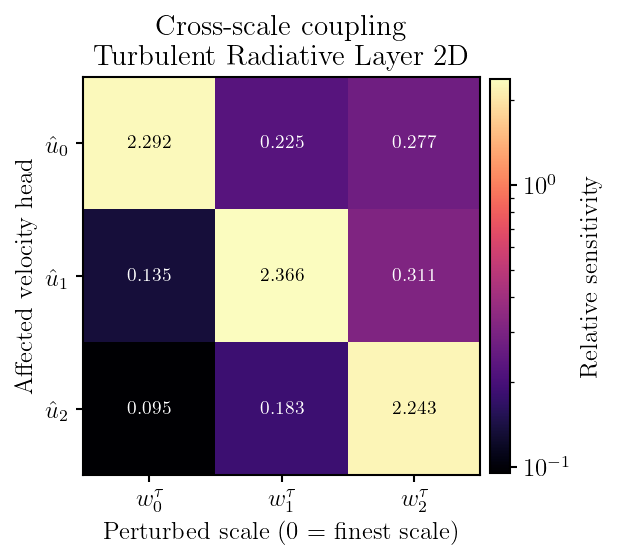

In [10]:
fig = csu.plot_sensitivity(
    sens,
    title    = f"Cross-scale coupling\nTurbulent Radiative Layer 2D",
    savepath = _Path(PROJECT_ROOT) / "artifacts" / "figures" / "cross_scale_sensitivity_trl.pdf",
)
#np.savez(results_dir / "cross_scale_sensitivity.npz",
#         matrices=sens["matrices"], mean=sens["mean"],
#         taus=sens["taus"], floor=sens["floor"])

### Robustness check

The measured coupling should not be an artefact of the perturbation size. Sweep
`delta` over two orders of magnitude — in the linear-response regime the
elasticity is flat.

In [11]:
for d in (1e-3, 1e-2, 1e-1):
    S, floor = csu.sensitivity_matrix(model, batch, tau=0.5, delta=d, n_probe=3)
    off = (S.sum() - np.trace(S)) / S.sum()
    print(f"delta = {d:6.0e}   off-diagonal mass = {off:6.1%}   "
          f"floor = {floor:.1e}")

delta =  1e-03   off-diagonal mass =  14.7%   floor = 0.0e+00
delta =  1e-02   off-diagonal mass =  14.7%   floor = 0.0e+00
delta =  1e-01   off-diagonal mass =  15.0%   floor = 0.0e+00


## 7. Rollout

Three fixes relative to the original notebook:

1. `NUM_SAMPLING_STEPS` was defined but never read — `rollout()` takes it from
   `flow_matching_cfg`. Now set explicitly.
2. `ode_method` defaulted to `"heun"` (2 NFE per step). Now explicit, and NFE
   is reported.
3. `clamp_sigma` defaulted to `5.0`, which truncates the fed-back state at 5σ.
   Set to `0.0` here: clipping the tails would destroy the very statistic
   section 8 measures. Section 7b checks whether it would have fired.

In [12]:
"""N_STEPS_INPUT      = 4
N_ROLLOUT_STEPS    = dataset.metadata.n_steps_per_trajectory[0] - N_STEPS_INPUT
NUM_SAMPLING_STEPS = 20
N_ENSEMBLE         = 1        # raise to 8 for CRPS
ODE_METHOD         = "euler"  # 2 NFE per step
CLAMP_SIGMA        = 0.0      # 0.0 = disabled

model.flow_matching_cfg.num_sampling_steps = NUM_SAMPLING_STEPS   # <- was ignored
model.flow_matching_cfg.n_ensemble         = N_ENSEMBLE

nfe = NUM_SAMPLING_STEPS * (2 if ODE_METHOD in ("heun", "midpoint") else 1)
print(f"{NUM_SAMPLING_STEPS} ODE steps x {ODE_METHOD} -> {nfe} NFE per frame")"""

'N_STEPS_INPUT      = 4\nN_ROLLOUT_STEPS    = dataset.metadata.n_steps_per_trajectory[0] - N_STEPS_INPUT\nNUM_SAMPLING_STEPS = 20\nN_ENSEMBLE         = 1        # raise to 8 for CRPS\nODE_METHOD         = "euler"  # 2 NFE per step\nCLAMP_SIGMA        = 0.0      # 0.0 = disabled\n\nmodel.flow_matching_cfg.num_sampling_steps = NUM_SAMPLING_STEPS   # <- was ignored\nmodel.flow_matching_cfg.n_ensemble         = N_ENSEMBLE\n\nnfe = NUM_SAMPLING_STEPS * (2 if ODE_METHOD in ("heun", "midpoint") else 1)\nprint(f"{NUM_SAMPLING_STEPS} ODE steps x {ODE_METHOD} -> {nfe} NFE per frame")'

In [13]:
"""torch.manual_seed(SEED)

preds_phys_all, preds_norm_all = [], []

with torch.inference_mode():
    for traj_idx in range(N_TRAJ):
        print(f"\n--- trajectory {traj_idx} ---")
        item          = dataset[traj_idx]
        x_full, label = get_well_inputs(item, device=device)
        seed_win      = x_full[:N_STEPS_INPUT]

        seed_exp  = seed_win.unsqueeze(0).expand(N_ENSEMBLE, -1, -1, -1, -1)
        label_exp = (label.unsqueeze(0).expand(N_ENSEMBLE, -1)
                     if label is not None else None)

        preds_norm, preds_phys = model.rollout(
            seed             = seed_exp,
            scalar_conds     = label_exp,
            rollout_steps    = N_ROLLOUT_STEPS,
            n_steps_input    = N_STEPS_INPUT,
            n_ensemble       = 1,
            normalized_input = False,
            verbose          = True,
            ode_method       = ODE_METHOD,
            clamp_sigma      = CLAMP_SIGMA,
        )
        preds_phys_all.append(preds_phys.squeeze(1).cpu())
        preds_norm_all.append(preds_norm.squeeze(1).cpu())

waveletfm_preds = torch.stack(preds_phys_all, dim=0)   # (N_TRAJ,E,T,H,W,C)
waveletfm_norm  = torch.stack(preds_norm_all, dim=0)
print("\npredictions:", tuple(waveletfm_preds.shape))"""

'torch.manual_seed(SEED)\n\npreds_phys_all, preds_norm_all = [], []\n\nwith torch.inference_mode():\n    for traj_idx in range(N_TRAJ):\n        print(f"\n--- trajectory {traj_idx} ---")\n        item          = dataset[traj_idx]\n        x_full, label = get_well_inputs(item, device=device)\n        seed_win      = x_full[:N_STEPS_INPUT]\n\n        seed_exp  = seed_win.unsqueeze(0).expand(N_ENSEMBLE, -1, -1, -1, -1)\n        label_exp = (label.unsqueeze(0).expand(N_ENSEMBLE, -1)\n                     if label is not None else None)\n\n        preds_norm, preds_phys = model.rollout(\n            seed             = seed_exp,\n            scalar_conds     = label_exp,\n            rollout_steps    = N_ROLLOUT_STEPS,\n            n_steps_input    = N_STEPS_INPUT,\n            n_ensemble       = 1,\n            normalized_input = False,\n            verbose          = True,\n            ode_method       = ODE_METHOD,\n            clamp_sigma      = CLAMP_SIGMA,\n        )\n        preds_phy

### 7b. Would the default clamp have fired?

If `fraction_clipped > 0`, then every result produced with the default
`clamp_sigma=5.0` was generated by a mechanism that truncates extreme values.
That is disqualifying for an intermittency argument and worth knowing.

In [14]:
rep = csu.clamp_report(waveletfm_norm, clamp_sigma=5.0)
print(rep)
if not rep["safe"]:
    print("\n[!] the default clamp_sigma=5.0 WOULD have truncated "
          f"{rep['fraction_clipped']:.3%} of values. "
          "Keep CLAMP_SIGMA=0.0 for all intermittency diagnostics.")

NameError: name 'waveletfm_norm' is not defined

In [ ]:
#save_path = (results_dir /
#             f"{ckpt_base_name}_rollout_nfe{nfe}_nens{N_ENSEMBLE}"
#             f"_{ODE_METHOD}_clamp{CLAMP_SIGMA}_traj.pkl")
#with open(save_path, "wb") as f:
#    pickle.dump(waveletfm_preds, f)
#print("saved:", save_path.name)

## 8. Cross-scale structure of the generated fields

The sensitivity matrix shows the heads *are* coupled. This section shows the
coupling produces the *right* structure — the distributional counterpart.

* **Detail kurtosis** per scale. Gaussian = 3; intermittent fields rise toward
  the fine scales.
* **Parent–child magnitude correlation** $\mathrm{Corr}(|d_i|, |d_{i+1}|)$.
  This is the scale-to-scale dependence that no marginal-matching model
  reproduces, and no metric in the current paper measures.

In [ ]:
TRAJ_FOR_STATS = 0

item_gt, _ = dataset[TRAJ_FOR_STATS], None
x_gt, _    = get_well_inputs(dataset[TRAJ_FOR_STATS], device=device)
truth      = x_gt[N_STEPS_INPUT:N_STEPS_INPUT + N_ROLLOUT_STEPS].cpu()

stats_truth = csu.wavelet_stats(model, truth)
stats_wfm   = csu.wavelet_stats(model, waveletfm_preds[TRAJ_FOR_STATS, 0])

for name, st in [("ground truth", stats_truth), ("WFM 3-scale", stats_wfm)]:
    ks = "  ".join(f"s{i}={v:5.2f}" for i, v in sorted(st["kurtosis"].items()))
    pc = "  ".join(f"({i},{i+1})={v:5.3f}"
                   for i, v in sorted(st["parent_child"].items()))
    print(f"{name:>14s} | kurtosis  {ks}")
    print(f"{'':>14s} | parent-child  {pc}")

### Positive control: scale-shuffled samples

Confirms the diagnostic has power. Rebuild fields by taking each scale from a
*different* time step, then inverse-transform. Cross-scale dependence is
destroyed by construction, so `parent_child` must collapse. If it does not,
the metric is not measuring what it claims and the comparison above is
meaningless.

In [ ]:
@torch.no_grad()
def scale_shuffled(model, fields, shift=7):
    """Take scale i from frame n, scale i+1 from frame n+shift*(i+1)."""
    from einops import rearrange
    f = fields.to(device=device, dtype=next(model.parameters()).dtype)
    f = model.normalizer.normalize_flattened(f, mode='variable')
    x = rearrange(f.unsqueeze(1), 'B T H W C -> B C T H W')
    coeffs = model.wavelet_decomposer.forward_transform(x)
    mixed = {i: torch.roll(c, shifts=shift * (i + 1), dims=0)
             for i, c in coeffs.items()}
    rec = model.wavelet_decomposer.inverse_transform(mixed)
    return rearrange(rec, 'B C T H W -> B T H W C').squeeze(1).cpu()

shuffled     = scale_shuffled(model, waveletfm_preds[TRAJ_FOR_STATS, 0])
stats_shuf   = csu.wavelet_stats(model, shuffled.unsqueeze(1).squeeze(1),
                                 normalize=False)

print("scale-shuffled control | parent-child  " + "  ".join(
    f"({i},{i+1})={v:5.3f}" for i, v in sorted(stats_shuf["parent_child"].items())))

In [ ]:
fig = csu.plot_wavelet_stats(
    {
        "ground truth":  stats_truth,
        "WFM 3-scale":   stats_wfm,
        "shuffled (control)": stats_shuf,
    },
    #savepath = results_dir / "wavelet_cross_scale_stats.pdf",
)

## 9. What to report

**Figure (section 6).** The $J \times J$ heatmap. Caption: relative change in
velocity head $\hat u_j$ under a 1% perturbation of the interpolant at scale
$w^\tau_{j'}$, averaged over $\tau$; off-diagonal entries would be identically
zero for independent per-scale flows.

**Numbers to quote.** Off-diagonal mass fraction, the determinism floor, and
the ratio between them. Note the asymmetry between backscatter and cascade
directions if one is present.

**Figure (section 8).** Kurtosis and parent–child correlation, truth vs. WFM
vs. shuffled control. The control is what makes the comparison credible.

**Free ablation.** Rerun section 8 with the 1-scale checkpoint. It has no
cross-scale coupling by construction; if its statistics are worse, that is an
ablation you already trained.